# Pandas Data Analysis Practice

Hands-on practice with **Pandas** and **Matplotlib** on a sample people dataset (`sample2.csv`, 463 records).

**Columns:** `id`, `f_name`, `l_name`, `age`, `profession`, `location`

**Topics covered**
1. Loading and inspecting data
2. Selecting columns and dropping columns
3. Filtering with single and multiple conditions
4. `loc` and `iloc` indexing
5. Updating values safely
6. Grouping and aggregation with `groupby`
7. Visualization (bar, histogram, pie, box plot)

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Load and inspect the data

In [2]:
df = pd.read_csv("sample2.csv")

# The source file spells the column "proffesion"; fix it for readability
df = df.rename(columns={"proffesion": "profession"})

# Normalise location text so "India" and "india" are treated as the same value
df["location"] = df["location"].str.strip().str.lower()

df.head()

,id,f_name,l_name,age,profession,location
0,4000001,Kristina,Chung,55,Pilot,india
1,4000002,Paige,Chen,74,Teacher,uk
2,4000003,Sherri,Melton,34,Firefighter,us
3,4000004,Gretchen,Hill,66,Computer hardware engineer,china
4,4000005,Karen,Puckett,74,Lawyer,africa


In [3]:
print("Shape:", df.shape)
df.columns

Shape: (463, 6)


Index(['id', 'f_name', 'l_name', 'age', 'profession', 'location'], dtype='str')

In [4]:
# Data types, non-null counts and memory usage
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 463 entries, 0 to 462
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   id          463 non-null    int64
 1   f_name      463 non-null    str  
 2   l_name      463 non-null    str  
 3   age         463 non-null    int64
 4   profession  463 non-null    str  
 5   location    462 non-null    str  
dtypes: int64(2), str(4)
memory usage: 21.8 KB


In [5]:
# Summary statistics for the numeric columns
df.describe()

,id,age
count,4.630000e+02,463.000000
mean,4.000232e+06,49.673866
std,1.338008e+02,15.606897
min,4.000001e+06,21.000000
25%,4.000116e+06,36.000000
50%,4.000232e+06,51.000000
75%,4.000348e+06,64.000000
max,4.000463e+06,75.000000


In [6]:
# Missing values per column
df.isnull().sum()

id            0
f_name        0
l_name        0
age           0
profession    0
location      1
dtype: int64

## 3. Selecting columns

In [7]:
# Two columns -> DataFrame (2-dimensional)
df[["f_name", "age"]].head()

,f_name,age
0,Kristina,55
1,Paige,74
2,Sherri,34
3,Gretchen,66
4,Karen,74


In [8]:
# One column -> Series (1-dimensional)
df["age"].head()

0    55
1    74
2    34
3    66
4    74
Name: age, dtype: int64

## 4. Dropping columns

`drop` returns a new DataFrame by default, so the original is unchanged. Use `inplace=True` or reassign to make the change permanent.

In [9]:
df.drop(columns=["age"]).head()

,id,f_name,l_name,profession,location
0,4000001,Kristina,Chung,Pilot,india
1,4000002,Paige,Chen,Teacher,uk
2,4000003,Sherri,Melton,Firefighter,us
3,4000004,Gretchen,Hill,Computer hardware engineer,china
4,4000005,Karen,Puckett,Lawyer,africa


In [10]:
df.drop(columns=["age", "profession"]).head()

,id,f_name,l_name,location
0,4000001,Kristina,Chung,india
1,4000002,Paige,Chen,uk
2,4000003,Sherri,Melton,us
3,4000004,Gretchen,Hill,china
4,4000005,Karen,Puckett,africa


## 5. Filtering rows

In [11]:
# Single condition: people older than 50
df[df["age"] > 50].head()

,id,f_name,l_name,age,profession,location
0,4000001,Kristina,Chung,55,Pilot,india
1,4000002,Paige,Chen,74,Teacher,uk
3,4000004,Gretchen,Hill,66,Computer hardware engineer,china
4,4000005,Karen,Puckett,74,Lawyer,africa
7,4000008,Hazel,Bender,63,Carpenter,india


In [12]:
# Filter rows, then select columns
df[df["age"] > 50][["f_name", "profession"]].head()

,f_name,profession
0,Kristina,Pilot
1,Paige,Teacher
3,Gretchen,Computer hardware engineer
4,Karen,Lawyer
7,Hazel,Carpenter


In [13]:
# AND (&): older than 50 and located in India
df[(df["age"] > 50) & (df["location"] == "india")]

,id,f_name,l_name,age,profession,location
0,4000001,Kristina,Chung,55,Pilot,india
7,4000008,Hazel,Bender,63,Carpenter,india
9,4000010,Dolores,McLaughlin,60,Writer,india
13,4000014,Beth,Woodard,65,Musician,india
15,4000016,Jerome,Wallace,52,Pharmacist,india
16,4000017,Neal,Lawrence,72,Computer support specialist,india
18,4000019,Kristine,Dougherty,63,Financial analyst,india
19,4000020,Crystal,Powers,67,Engineering technician,india
21,4000022,Eric,Steele,66,Doctor,india
26,4000027,Marcia,Walsh,64,Accountant,india


In [14]:
# AND (&) with column selection
df[(df["age"] > 40) & (df["location"] == "china")][["f_name", "location"]]

,f_name,location
3,Gretchen,china
140,Jeff,china
141,Sandra,china
143,Raymond,china
146,Kathy,china
147,Troy,china
150,Jack,china
154,Tamara,china
155,Mitchell,china
156,Franklin,china


In [15]:
# OR (|): located in India or the UK
df[(df["location"] == "india") | (df["location"] == "uk")].head()

,id,f_name,l_name,age,profession,location
0,4000001,Kristina,Chung,55,Pilot,india
1,4000002,Paige,Chen,74,Teacher,uk
7,4000008,Hazel,Bender,63,Carpenter,india
8,4000009,Malcolm,Wagner,39,Artist,india
9,4000010,Dolores,McLaughlin,60,Writer,india


## 6. Slicing rows

Square-bracket slicing selects rows by position (the end index is excluded).

In [16]:
df[0:5]

,id,f_name,l_name,age,profession,location
0,4000001,Kristina,Chung,55,Pilot,india
1,4000002,Paige,Chen,74,Teacher,uk
2,4000003,Sherri,Melton,34,Firefighter,us
3,4000004,Gretchen,Hill,66,Computer hardware engineer,china
4,4000005,Karen,Puckett,74,Lawyer,africa


In [17]:
df[10:20][["f_name", "location"]]

,f_name,location
10,Francis,india
11,Sandy,india
12,Marion,india
13,Beth,india
14,Julia,india
15,Jerome,india
16,Neal,india
17,Jean,india
18,Kristine,india
19,Crystal,india


## 7. `loc` : label-based indexing

`df.loc[rows, columns]` selects, filters and updates rows and columns by label or boolean condition. The end of a label slice is **included**.

In [18]:
df.loc[10:21, ["f_name", "profession"]]

,f_name,profession
10,Francis,Therapist
11,Sandy,Writer
12,Marion,Carpenter
13,Beth,Musician
14,Julia,Musician
15,Jerome,Pharmacist
16,Neal,Computer support specialist
17,Jean,Childcare worker
18,Kristine,Financial analyst
19,Crystal,Engineering technician


In [19]:
df.loc[df["age"] > 40, ["f_name", "age"]].head()

,f_name,age
0,Kristina,55
1,Paige,74
3,Gretchen,66
4,Karen,74
5,Patrick,42


In [20]:
# Age between 40 and 60 (inclusive)
df.loc[(df["age"] >= 40) & (df["age"] <= 60), ["f_name", "profession"]].head()

,f_name,profession
0,Kristina,Pilot
5,Patrick,Veterinarian
6,Elsie,Pilot
9,Dolores,Writer
10,Francis,Therapist


In [21]:
# Musicians or therapists
df.loc[(df["profession"] == "Musician") | (df["profession"] == "Therapist"), ["f_name", "location"]]

,f_name,location
10,Francis,india
13,Beth,india
14,Julia,india
24,Claire,india
44,Lois,uk
72,Arlene,us
78,Stacy,us
96,Brandon,us
127,Joanne,us
144,Roger,china


## 8. Updating values with `loc`

These updates are done on a **copy** (`df_demo`) so the original `df` stays unchanged for the analysis below.

In [22]:
df_demo = df.copy()

df_demo.loc[df_demo["age"] > 60, "profession"] = "Senior"
df_demo.loc[(df_demo["age"] >= 50) & (df_demo["age"] <= 60), "location"] = "india"

df_demo[df_demo["age"] > 60].head()

,id,f_name,l_name,age,profession,location
1,4000002,Paige,Chen,74,Senior,uk
3,4000004,Gretchen,Hill,66,Senior,china
4,4000005,Karen,Puckett,74,Senior,africa
7,4000008,Hazel,Bender,63,Senior,india
13,4000014,Beth,Woodard,65,Senior,india


## 9. `iloc` : position-based indexing

`df.iloc[row_positions, column_positions]` selects by integer position. The end of a slice is **excluded**.

In [23]:
df.iloc[3, 4]    # single value: row 3, column 4

'Computer hardware engineer'

In [24]:
df.iloc[3]       # the complete row

id                               4000004
f_name                          Gretchen
l_name                              Hill
age                                   66
profession    Computer hardware engineer
location                           china
Name: 3, dtype: object

In [25]:
df.iloc[0:5, [1, 5]]       # first name and location, first five rows

,f_name,location
0,Kristina,india
1,Paige,uk
2,Sherri,us
3,Gretchen,china
4,Karen,africa


In [26]:
df.iloc[:, [1, 5]].head()  # first name and location, all rows

,f_name,location
0,Kristina,india
1,Paige,uk
2,Sherri,us
3,Gretchen,china
4,Karen,africa


In [27]:
df.iloc[-5:]               # last five rows

,id,f_name,l_name,age,profession,location
458,4000459,Gretchen,Francis,60,Politician,ireland
459,4000460,Cheryl,Horn,40,Veterinarian,ireland
460,4000461,Audrey,Forrest,50,Architect,ireland
461,4000462,Alan,Levin,43,Statistician,ireland
462,4000463,Wayne,Weiner,70,Actor,ireland


In [28]:
df.iloc[[1, 10, 14], [1, 4, 5]]  # specific rows and columns

,f_name,profession,location
1,Paige,Teacher,uk
10,Francis,Therapist,india
14,Julia,Musician,india


## 10. Grouping and aggregation

In [29]:
# Average age by location
df.groupby("location")["age"].mean()

location
africa       52.539326
australia    49.019231
china        49.607143
india        50.095238
ireland      49.636364
uk           45.540541
us           49.102564
Name: age, dtype: float64

In [30]:
# Maximum age in each profession
df.groupby("profession")["age"].max().head(10)

profession
Accountant                         64
Actor                              73
Agricultural and food scientist    70
Architect                          66
Artist                             75
Athlete                            69
Automotive mechanic                70
Carpenter                          66
Chemist                            70
Childcare worker                   72
Name: age, dtype: int64

In [31]:
# Number of people in each profession
df.groupby("profession").size().sort_values(ascending=False).head(10)

profession
Childcare worker               17
Photographer                   15
Musician                       15
Loan officer                   14
Pilot                          13
Doctor                         13
Veterinarian                   13
Computer support specialist    12
Actor                          12
Statistician                   11
dtype: int64

In [32]:
# Several statistics at once
df.groupby("profession")["age"].agg(["mean", "min", "max", "size"]).head(10)

,mean,min,max,size
profession,,,,
Accountant,54.888889,36,64,9
Actor,58.000000,35,73,12
Agricultural and food scientist,46.222222,28,70,9
Architect,44.500000,21,66,8
Artist,50.500000,39,75,8
Athlete,51.222222,33,69,9
Automotive mechanic,47.000000,30,70,6
Carpenter,49.700000,23,66,10
Chemist,51.833333,32,70,6


In [33]:
# Group by two columns
df.groupby(["profession", "location"]).size().head(10)

profession                       location 
Accountant                       africa       4
                                 australia    3
                                 india        1
                                 ireland      1
Actor                            africa       3
                                 china        2
                                 ireland      4
                                 uk           1
                                 us           2
Agricultural and food scientist  africa       1
dtype: int64

In [34]:
# Average age by profession, highest first
df.groupby("profession")["age"].mean().sort_values(ascending=False).head(10)

profession
Computer software engineer    58.142857
Actor                         58.000000
africa                        58.000000
Social worker                 55.900000
Civil engineer                55.727273
Photographer                  55.400000
Accountant                    54.888889
Financial analyst             53.500000
Computer hardware engineer    52.857143
Therapist                     52.500000
Name: age, dtype: float64

## 11. Visualization

### Average age by location

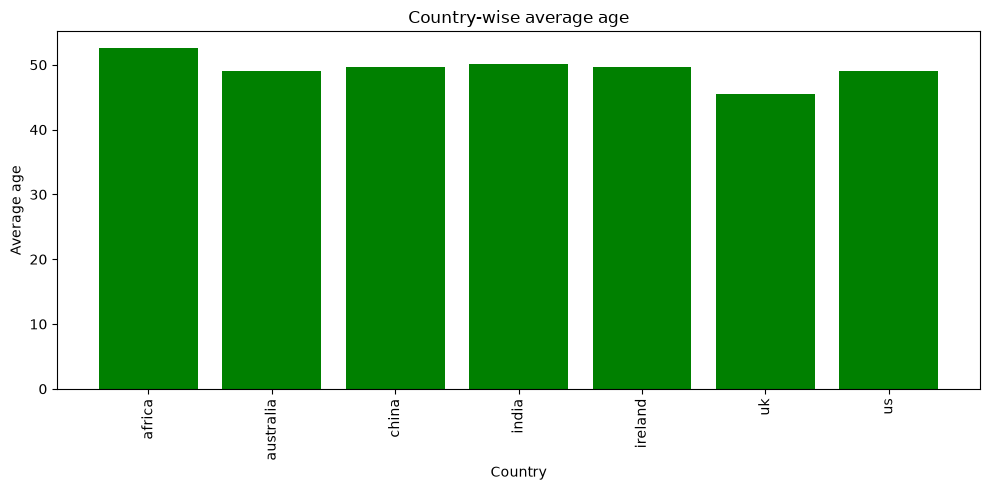

In [35]:
avg_age = df.groupby("location")["age"].mean()

plt.figure(figsize=(10, 5))
plt.bar(avg_age.index, avg_age.values, color="g")
plt.title("Country-wise average age")
plt.xlabel("Country")
plt.ylabel("Average age")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### Number of people by location

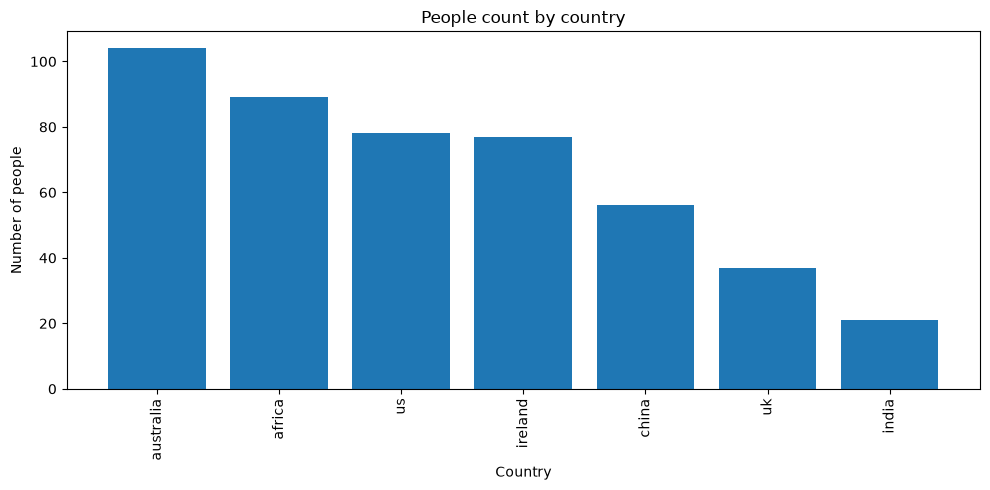

In [36]:
people_count = df["location"].value_counts()

plt.figure(figsize=(10, 5))
plt.bar(people_count.index, people_count.values)
plt.title("People count by country")
plt.xlabel("Country")
plt.ylabel("Number of people")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### Top 10 professions

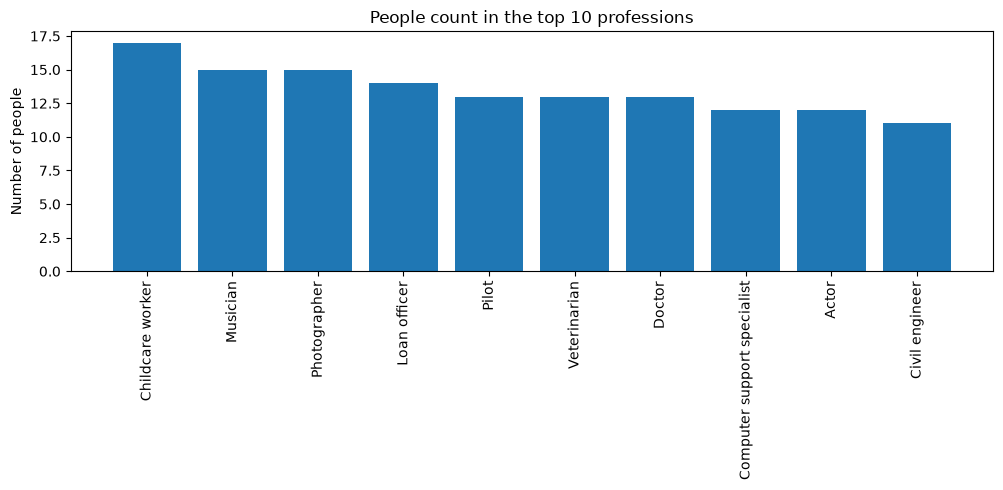

In [37]:
top_professions = df["profession"].value_counts().head(10)

plt.figure(figsize=(10, 5))
plt.bar(top_professions.index, top_professions.values)
plt.title("People count in the top 10 professions")
plt.xticks(rotation=90)   # prevents label overlap
plt.ylabel("Number of people")
plt.tight_layout()
plt.show()

### Maximum age by location

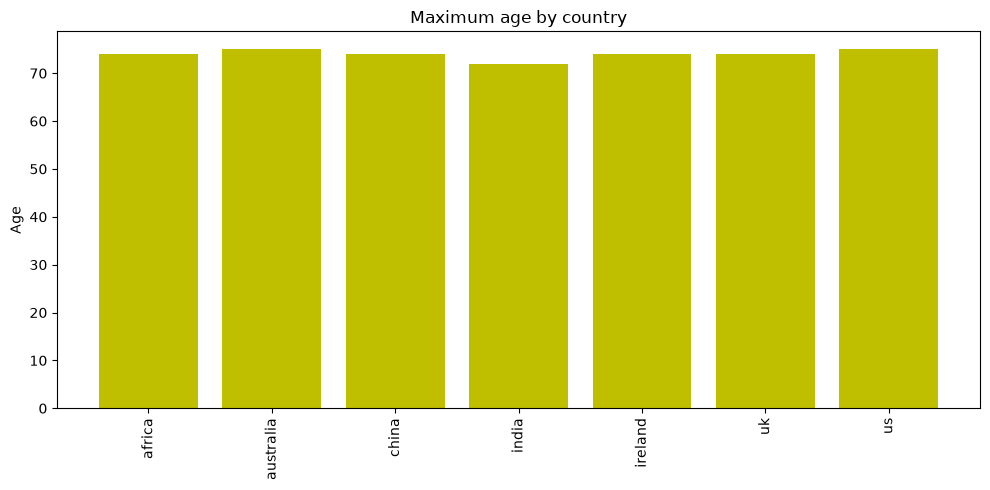

In [38]:
max_age = df.groupby("location")["age"].max()

plt.figure(figsize=(10, 5))
plt.bar(max_age.index, max_age.values, color="y")
plt.title("Maximum age by country")
plt.xticks(rotation=90)
plt.ylabel("Age")
plt.tight_layout()
plt.show()

### Age distribution (histogram)

A histogram shows how numerical data is distributed across intervals.

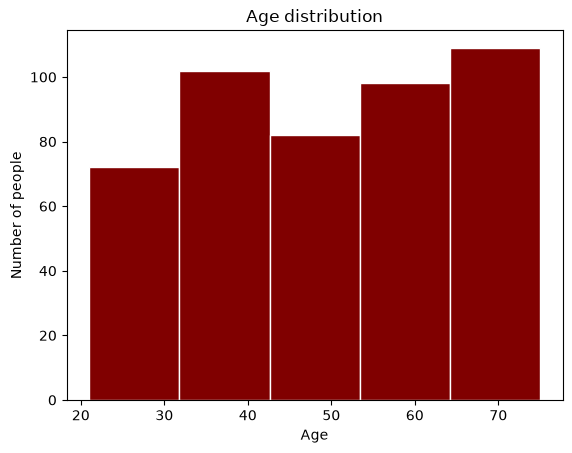

In [39]:
plt.hist(df["age"], bins=5, color="maroon", edgecolor="white")
plt.title("Age distribution")
plt.xlabel("Age")
plt.ylabel("Number of people")
plt.show()

### Share of people by location (pie chart)

`autopct` converts the values to percentages. Only the top 5 locations are shown to keep the chart readable.

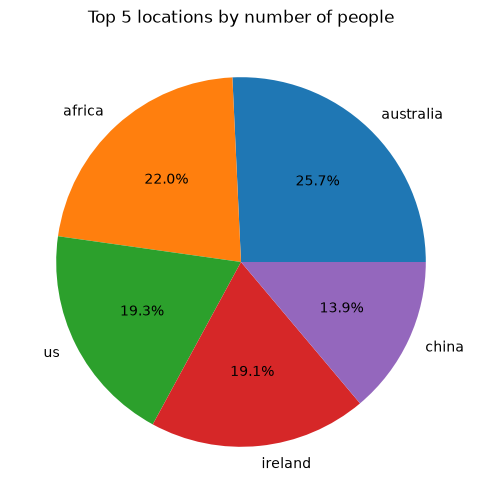

In [40]:
top_locations = df["location"].value_counts().head(5)

plt.figure(figsize=(6, 6))
plt.pie(top_locations.values, labels=top_locations.index, autopct="%1.1f%%")
plt.title("Top 5 locations by number of people")
plt.show()

### Minimum, maximum and average age

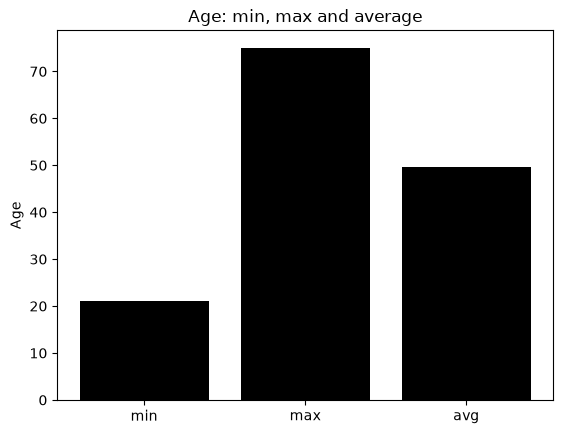

In [41]:
labels = ["min", "max", "avg"]
values = [df["age"].min(), df["age"].max(), df["age"].mean()]

plt.bar(labels, values, color="k")
plt.title("Age: min, max and average")
plt.ylabel("Age")
plt.show()

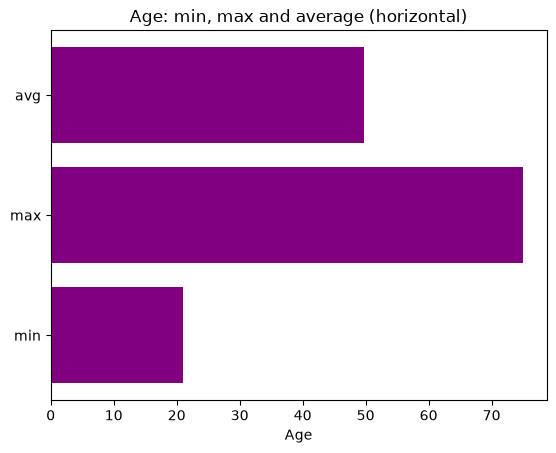

In [42]:
plt.barh(labels, values, color="purple")
plt.title("Age: min, max and average (horizontal)")
plt.xlabel("Age")
plt.show()

### Age spread (box plot)

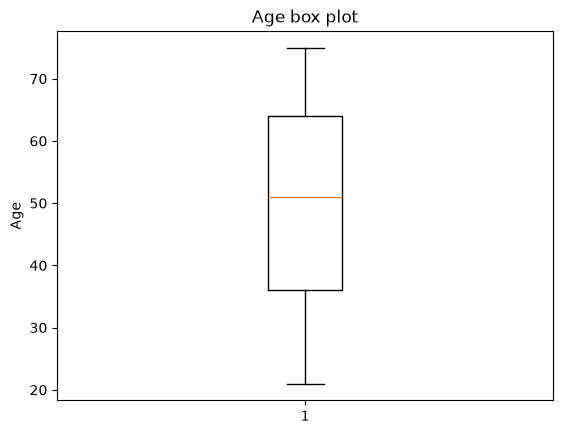

In [43]:
plt.boxplot(df["age"])
plt.title("Age box plot")
plt.ylabel("Age")
plt.show()

## 12. Key takeaways

- The dataset has **463 records**; ages range from **21 to 75** with a mean of about **49.7** and a median of **51**.
- `location` has **one missing value**, which is worth handling (drop or fill) before any serious analysis.
- `loc` selects by label and includes the slice end; `iloc` selects by position and excludes it.
- Boolean filters need parentheses around each condition when combined with `&` or `|`.
- Updating values on a copy (`df.copy()`) keeps the original data safe for later analysis.